# Results for the pitch

Six slide-ready charts, each saved as a PNG in `artifacts/charts/`. Every number comes from Fonecta's own scorer
(`evaluation/evaluate.py`) or from the result files written by `scripts/train.py`, `scripts/eval_ablations.py` and
`scripts/eval_autopilot.py`; the analysis behind them is in `01_data_and_models.ipynb`.

Colour key used throughout: **blue = our engine**, **gray = Fonecta's baseline** (copy last year → shopping centre →
peers). Values are written on the bars, so the charts also read in black and white.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cs.engine import data as D, decide as DC
CACHE, CHARTS = D.CACHE, ROOT / "artifacts" / "charts"; CHARTS.mkdir(parents=True, exist_ok=True)

# reference palette (validated: scripts/validate_palette.py, light surface)
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, BASE = "#2a78d6", "#eb6834", "#1baf7a", "#a9a79f"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "font.size": 11,
                     "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"], "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.major.size": 0,
                     "ytick.major.size": 0, "legend.frameon": False})

def titled(fig, title, subtitle):
    fig.text(0.02, 0.97, title, fontsize=15, fontweight="bold", color=INK, va="top")
    fig.text(0.02, 0.905, subtitle, fontsize=10.5, color=INK2, va="top")

def bar_pair(ax, groups, base_vals, eng_vals, fmt="{:.1f}", eng_err=None, base_err=None, width=0.34):
    x = np.arange(len(groups))
    for off, vals, col, err, lbl in ((-width / 2 - 0.02, base_vals, BASE, base_err, "Fonecta baseline"),
                                     (width / 2 + 0.02, eng_vals, BLUE, eng_err, "Our engine")):
        bars = ax.bar(x + off, vals, width, color=col, label=lbl, zorder=2)
        for i, b in enumerate(bars):
            top = b.get_height() + (err[1][i] if err is not None else 0)
            ax.text(b.get_x() + b.get_width() / 2, top, fmt.format(vals[i]), ha="center", va="bottom", fontsize=11,
                    color=INK, fontweight="bold")
        if err is not None:
            ax.errorbar(x + off, vals, yerr=err, fmt="none", ecolor=INK2, elinewidth=1.2, capsize=4, zorder=3)
    ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=11, color=INK)
    ax.legend(loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=10, handlelength=1.0)
    return x

def evaluate(pred, season):
    out = subprocess.run([sys.executable, str(D.DS / "evaluation" / "evaluate.py"), "--predictions", str(pred),
                          "--labels", str(D.labels_path(season)), "--json"], capture_output=True, text=True, check=True)
    return json.loads(out.stdout)

OFF = {(who, s): evaluate(p, s) for s in (2026, 2025) for who, p in
       (("engine", ROOT / "outputs" / f"engine_predictions_{s}.csv"), ("baseline", D.DS / "outputs" / f"baseline_predictions_{s}.csv"))}
pd.DataFrame({f"{w} {s}": {k: v[k] for k in ("score_0_100", "harmful_suggestions", "precision_exact", "recall_exact",
             "closed_door_views_prevented_pct", "search_views_protected_pct")} for (w, s), v in OFF.items()})

,engine 2026,baseline 2026,engine 2025,baseline 2025
score_0_100,61.670,54.490,55.420,53.230
harmful_suggestions,219.000,224.000,211.000,249.000
precision_exact,0.859,0.901,0.866,0.899
recall_exact,0.670,0.590,0.597,0.578
closed_door_views_prevented_pct,72.900,69.200,66.200,67.700
search_views_protected_pct,65.000,57.200,56.300,55.100


## (a) Score against the baseline, with 95% intervals

The interval comes from resampling dev **businesses** (not rows) until the sample has the size of the hidden test set
(30,398 rows), 2,000 times.

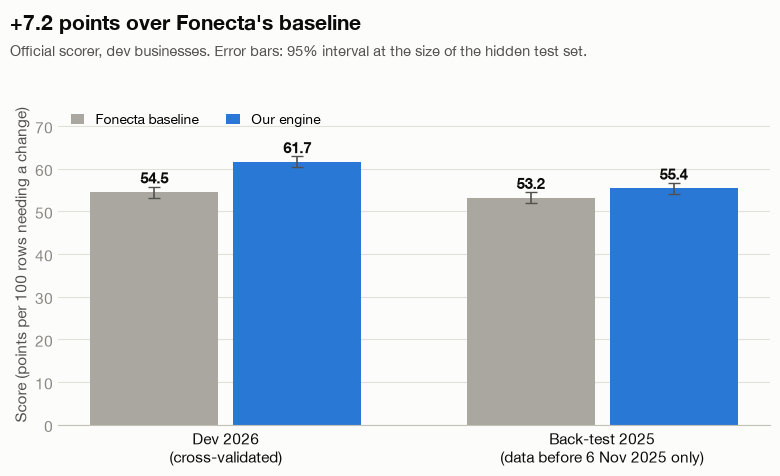

{2026: {'engine': 61.67, 'baseline': 54.49, 'engine_ci': [60.38, 62.86], 'baseline_ci': [53.15, 55.78]}, 2025: {'engine': 55.42, 'baseline': 53.23, 'engine_ci': [54.18, 56.67], 'baseline_ci': [51.89, 54.48]}}


In [2]:
def row_points(pred_csv, season):
    lab = D.labels(season)
    p = pd.read_csv(pred_csv, dtype=str).fillna("")
    m = lab[["entity_id", "date"]].merge(p, on=["entity_id", "date"], how="left").fillna({"action": "NO_ACTION", "hours": ""})
    return lab, np.array([DC.points(a, h, t, s, e) for a, h, t, s, e in zip(m.action, m.hours, lab.truth_hours,
                          lab.displayed_hours_at_snapshot, lab.expected_action)])

def boot_ci(lab, pts_list, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    uniq, inv = np.unique(lab.entity_id.values, return_inverse=True)
    need = np.bincount(inv, weights=(lab.expected_action.values != "NO_ACTION").astype(float))
    sums = [np.bincount(inv, weights=p) for p in pts_list]
    n_b = int(round(len(uniq) * 30398 / len(lab)))
    res = np.array([[100 * s[idx].sum() / need[idx].sum() for s in sums]
                    for idx in (rng.integers(0, len(uniq), n_b) for _ in range(n_boot))])
    return np.percentile(res, [2.5, 97.5], axis=0)

A = {}
for s in (2026, 2025):
    lab, pe = row_points(ROOT / "outputs" / f"engine_predictions_{s}.csv", s)
    _, pb = row_points(D.DS / "outputs" / f"baseline_predictions_{s}.csv", s)
    ci = boot_ci(lab, [pe, pb])
    A[s] = {"engine": 100 * pe.sum() / (lab.expected_action != "NO_ACTION").sum(), "baseline": 100 * pb.sum() / (lab.expected_action != "NO_ACTION").sum(),
            "engine_ci": ci[:, 0], "baseline_ci": ci[:, 1]}
groups = ["Dev 2026\n(cross-validated)", "Back-test 2025\n(data before 6 Nov 2025 only)"]
eng = [A[2026]["engine"], A[2025]["engine"]]; base = [A[2026]["baseline"], A[2025]["baseline"]]
e_err = np.array([[A[s]["engine"] - A[s]["engine_ci"][0] for s in (2026, 2025)], [A[s]["engine_ci"][1] - A[s]["engine"] for s in (2026, 2025)]])
b_err = np.array([[A[s]["baseline"] - A[s]["baseline_ci"][0] for s in (2026, 2025)], [A[s]["baseline_ci"][1] - A[s]["baseline"] for s in (2026, 2025)]])
fig, ax = plt.subplots(figsize=(8, 5)); fig.subplots_adjust(top=0.78, bottom=0.14, left=0.08, right=0.97)
ax.set_ylim(0, 75)
bar_pair(ax, groups, base, eng, eng_err=e_err, base_err=b_err)
ax.set_ylabel("Score (points per 100 rows needing a change)")
titled(fig, f"+{eng[0] - base[0]:.1f} points over Fonecta's baseline",
       "Official scorer, dev businesses. Error bars: 95% interval at the size of the hidden test set.")
fig.savefig(CHARTS / "a_score_vs_baseline.png", dpi=200); plt.show()
print({s: {k: (np.round(v, 2).tolist() if hasattr(v, "tolist") else round(v, 2)) for k, v in A[s].items()} for s in A})

**How to read this.** Each pair of bars is one season: gray is what Fonecta's rule-based baseline scores, blue is our
engine, both measured by Fonecta's own scorer on the dev businesses. The black whiskers show the range we expect on
the hidden test set (95% of resampled test-sized draws fall inside). On 2026 the intervals don't overlap, so the gain
is not luck. The 2025 back-test only uses data that existed on 6 Nov 2025; the gain is smaller there because the
entry history was only one season deep at that time, and a business's own past is the strongest signal.

## (b) Harmful suggestions ("closed" when open, or the reverse)

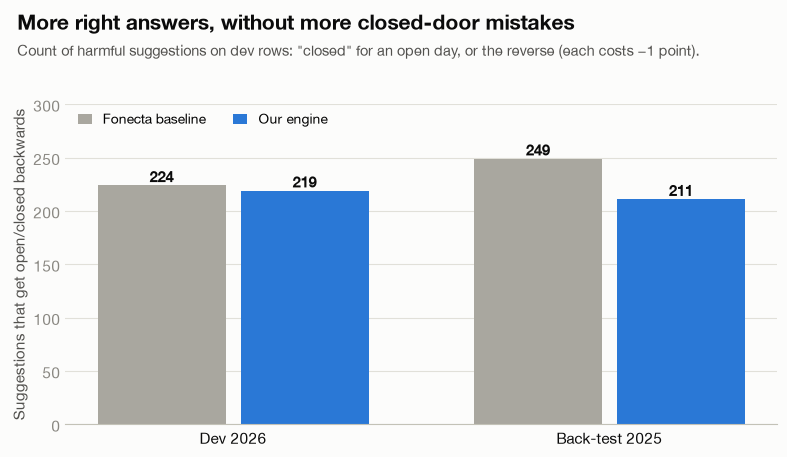

In [3]:
fig, ax = plt.subplots(figsize=(8, 5)); fig.subplots_adjust(top=0.78, bottom=0.14, left=0.08, right=0.97)
ax.set_ylim(0, 300)
hb = [OFF[("baseline", 2026)]["harmful_suggestions"], OFF[("baseline", 2025)]["harmful_suggestions"]]
he = [OFF[("engine", 2026)]["harmful_suggestions"], OFF[("engine", 2025)]["harmful_suggestions"]]
bar_pair(ax, ["Dev 2026", "Back-test 2025"], hb, he, fmt="{:.0f}")
ax.set_ylabel("Suggestions that get open/closed backwards")
titled(fig, "More right answers, without more closed-door mistakes",
       "Count of harmful suggestions on dev rows: \"closed\" for an open day, or the reverse (each costs −1 point).")
fig.savefig(CHARTS / "b_harmful_vs_baseline.png", dpi=200); plt.show()

**How to read this.** A harmful suggestion tells the owner "closed" on a day they are open, or the reverse: the worst
mistake, so the plan required us not to make more of them than the baseline. Lower is better. We make slightly fewer
than the baseline while getting many more days right (chart a), because every suggestion is weighed by its expected
points and a flip of open/closed needs extra evidence unless the owner's own past backs it.

## (c) Lookups that land on the right hours

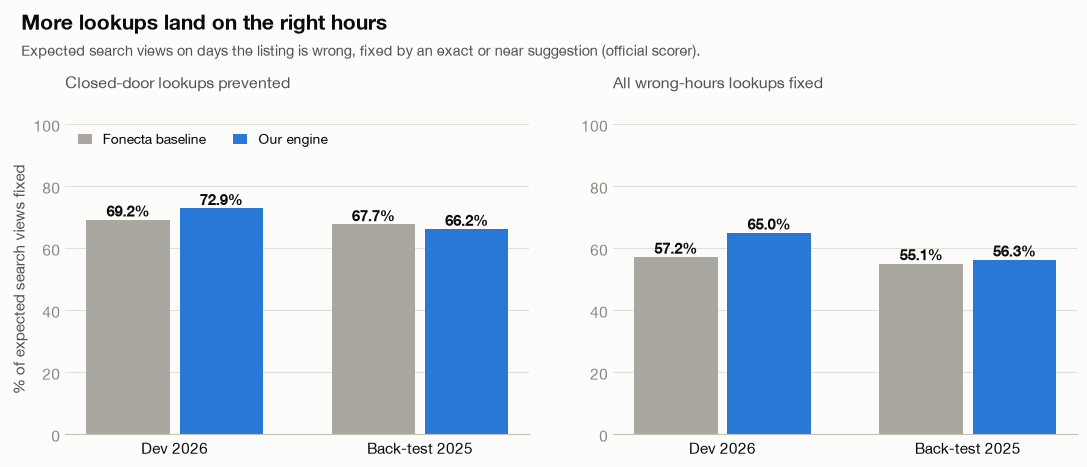

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5)); fig.subplots_adjust(top=0.74, bottom=0.12, left=0.06, right=0.98, wspace=0.18)
for ax, key, ttl in ((axs[0], "closed_door_views_prevented_pct", "Closed-door lookups prevented"),
                     (axs[1], "search_views_protected_pct", "All wrong-hours lookups fixed")):
    ax.set_ylim(0, 100)
    bar_pair(ax, ["Dev 2026", "Back-test 2025"], [OFF[("baseline", s_)][key] for s_ in (2026, 2025)],
             [OFF[("engine", s_)][key] for s_ in (2026, 2025)], fmt="{:.1f}%")
    ax.set_title(ttl, loc="left", fontsize=11.5, color=INK2, pad=26)
axs[0].set_ylabel("% of expected search views fixed")
axs[1].get_legend().remove()
titled(fig, "More lookups land on the right hours",
       "Expected search views on days the listing is wrong, fixed by an exact or near suggestion (official scorer).")
fig.savefig(CHARTS / "c_closed_door_views.png", dpi=200); plt.show()

**How to read this.** Fonecta's scorer weighs every wrong day by how many people are expected to look the business up
that day. Left: only the worst case, a listing that says "open" when the door is closed. Right: every day whose hours
are wrong. Each bar is the share of those lookups that our suggestions fix (exact hours, or within 30 minutes); higher
is better. On 2026 we fix more of both. On the 2025 back-test we fix more lookups overall but slightly fewer
closed-door ones (66.2% vs 67.7%): with only one season of history, the engine asks for stronger evidence before
telling an owner "closed", which is the same caution that keeps its harmful count below the baseline's (chart b).

## (d) Learning: with vs without the 2025 pilot feedback

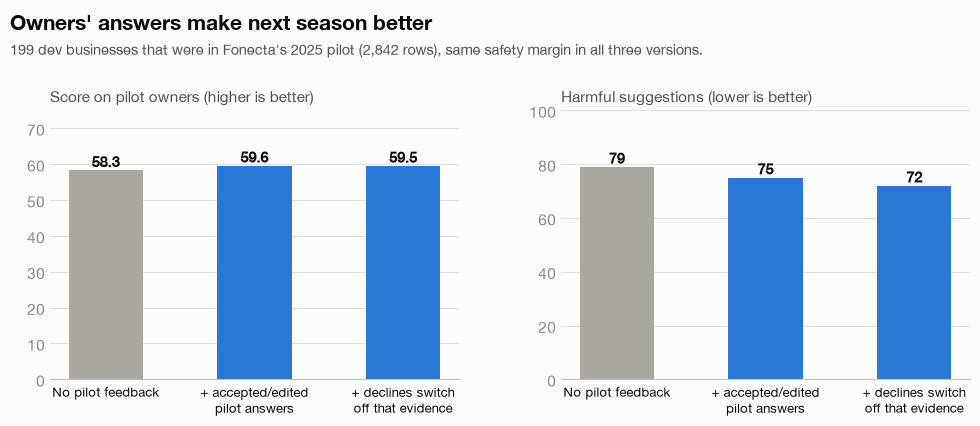

In [5]:
nbm = json.load(open(CACHE / "nb_metrics.json"))
b5 = {r["version"]: r for r in nbm["B5"]}
labels_ = ["No pilot feedback", "+ accepted/edited\npilot answers", "+ declines switch\noff that evidence"]
sc = [b5["without accepted/edited pilot entries"]["pilot owners' score"], b5["with accepted/edited pilot entries"]["pilot owners' score"],
      b5["decline rule on"]["pilot owners' score"]]
hm = [b5["without accepted/edited pilot entries"]["harmful"], b5["with accepted/edited pilot entries"]["harmful"], b5["decline rule on"]["harmful"]]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.8)); fig.subplots_adjust(top=0.76, bottom=0.2, left=0.06, right=0.98, wspace=0.25)
for ax, vals, ttl, fmt, top in ((axs[0], sc, "Score on pilot owners (higher is better)", "{:.1f}", 75),
                                (axs[1], hm, "Harmful suggestions (lower is better)", "{:.0f}", 100)):
    cols = [BASE, BLUE, BLUE]
    bars = ax.bar(range(3), vals, 0.5, color=cols, zorder=2); ax.set_ylim(0, top)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=11, fontweight="bold", color=INK)
    ax.set_xticks(range(3)); ax.set_xticklabels(labels_, fontsize=9.5, color=INK); ax.set_title(ttl, loc="left", fontsize=11, color=INK2)
titled(fig, "Owners' answers make next season better",
       "199 dev businesses that were in Fonecta's 2025 pilot (2,842 rows), same safety margin in all three versions.")
fig.savefig(CHARTS / "d_learning_feedback.png", dpi=200); plt.show()

**How to read this.** We replay the 2025 pilot as feedback and score the 2026 season for the owners who took part.
Left: the score; right: the harmful mistakes. Gray is the engine without any of the pilot's answers. Adding the
answers owners accepted or edited raises the score; also using their *declines* ("not right", "we're open as
usual") removes harmful suggestions without costing points, because we never repeat what an owner rejected. The
effect is modest because only one pilot season exists; in production every reply adds to it.

## (e) A customer with no history

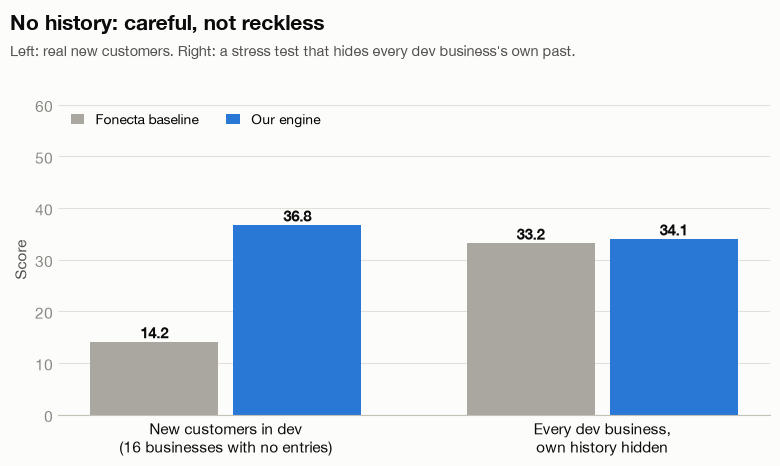

36.8 14.2 219


In [6]:
abl = json.load(open(CACHE / "ablations.json")); bnh = json.load(open(CACHE / "baseline_nohistory_2026.json"))
r = pd.read_parquet(CACHE / "oof_r_2026.parquet"); lab = D.labels(2026)
nh = (r.n_all.values == 0)
_, pe = row_points(ROOT / "outputs" / "engine_predictions_2026.csv", 2026)
_, pb = row_points(D.DS / "outputs" / "baseline_predictions_2026.csv", 2026)
den = (lab.expected_action.values[nh] != "NO_ACTION").sum()
new_e, new_b = 100 * pe[nh].sum() / den, 100 * pb[nh].sum() / den
groups = [f"New customers in dev\n({r[nh].entity_id.nunique()} businesses with no entries)", "Every dev business,\nown history hidden"]
fig, ax = plt.subplots(figsize=(8, 5)); fig.subplots_adjust(top=0.78, bottom=0.16, left=0.08, right=0.97)
ax.set_ylim(0, 60)
bar_pair(ax, groups, [new_b, bnh["score"]], [new_e, abl["no_history_masked"]["score"]])
ax.set_ylabel("Score")
titled(fig, "No history: careful, not reckless",
       "Left: real new customers. Right: a stress test that hides every dev business's own past.")
fig.savefig(CHARTS / "e_no_history.png", dpi=200); plt.show()
print(round(new_e, 1), round(new_b, 1), int(nh.sum()))

**How to read this.** Without a business's own past, every method loses most of its points: the right-hand pair
hides the history of all dev businesses, and both methods drop to about a third of their normal score. For real new
customers (left; only 16 businesses, so read it as a direction rather than a precise number), our engine stays well
ahead because it only suggests what similar businesses and the shopping centre make near-certain, and stays quiet
otherwise, where the baseline guesses. This is also why the season card
asks a new customer one well-chosen question: one answer is worth more than any amount of peer data.

## (f) Season Autopilot: lookups covered with zero owner replies

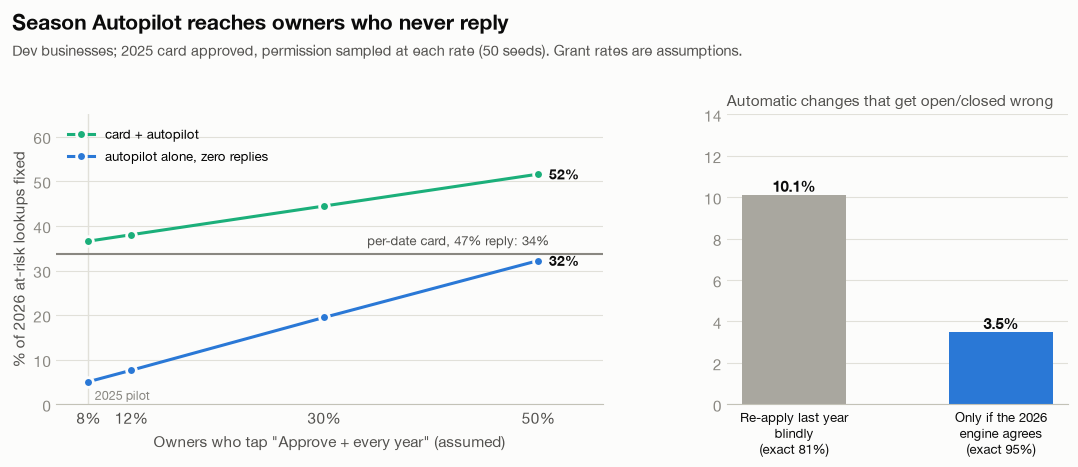

,grant_rate,gated_coverage_mean,auto_coverage_mean,card_only_coverage_mean,gated_combined_coverage_mean
0,0.08,0.051,0.071,0.338,0.366
1,0.12,0.076,0.107,0.338,0.380
2,0.30,0.195,0.274,0.338,0.444
3,0.50,0.322,0.454,0.338,0.516


In [7]:
ap = json.load(open(CACHE / "autopilot_eval.json")); cv = pd.DataFrame(ap["curve"])
g = cv.grant_rate.values * 100
fig, axs = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1.6, 1]})
fig.subplots_adjust(top=0.76, bottom=0.18, left=0.06, right=0.98, wspace=0.28)
ax = axs[0]
card = cv.card_only_coverage_mean.mean() * 100
ax.axhline(card, color=MUTED, lw=1.5, zorder=1)
ax.text(51, card + 1.2, f"per-date card, 47% reply: {card:.0f}%", ha="right", va="bottom", fontsize=9.5, color=INK2)
for col, key, name in ((AQUA, "gated_combined_coverage_mean", "card + autopilot"),
                       (BLUE, "gated_coverage_mean", "autopilot alone, zero replies")):
    ax.plot(g, cv[key] * 100, color=col, lw=2.2, marker="o", ms=7, mec=SURF, mew=2, zorder=3, label=name)
    ax.text(g[-1] + 1, cv[key].values[-1] * 100, f"{cv[key].values[-1] * 100:.0f}%", va="center", fontsize=10, color=INK, fontweight="bold")
ax.set_xticks(g); ax.set_xticklabels([f"{x:.0f}%" for x in g]); ax.set_xlim(5, 56); ax.set_ylim(0, 65)
ax.set_xlabel("Owners who tap \"Approve + every year\" (assumed)"); ax.set_ylabel("% of 2026 at-risk lookups fixed")
ax.legend(loc="upper left", fontsize=9.5)
ax.axvline(8, color=GRID, lw=1, zorder=0); ax.text(8.6, 1.0, "2025 pilot", fontsize=9, color=MUTED)
ax2 = axs[1]
eg, eu = ap["error_rate_of_gated_changes"], ap["error_rate_of_automatic_changes"]
vals = [eu["wrong_open_closed_total"] * 100, eg["wrong_open_closed_total"] * 100]
bars = ax2.bar([0, 1], vals, 0.5, color=[BASE, BLUE], zorder=2)
for b, v in zip(bars, vals):
    ax2.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=11, fontweight="bold", color=INK)
ax2.set_xticks([0, 1]); ax2.set_xticklabels([f"Re-apply last year\nblindly\n(exact {eu['exact'] * 100:.0f}%)",
                                             f"Only if the 2026\nengine agrees\n(exact {eg['exact'] * 100:.0f}%)"], fontsize=9.5, color=INK)
ax2.set_ylim(0, 14)
ax2.set_title("Automatic changes that get open/closed wrong", loc="left", fontsize=11, color=INK2)
titled(fig, "Season Autopilot reaches owners who never reply",
       "Dev businesses; 2025 card approved, permission sampled at each rate (50 seeds). Grant rates are assumptions.")
fig.savefig(CHARTS / "f_autopilot_coverage.png", dpi=200); plt.show()
cv[["grant_rate", "gated_coverage_mean", "auto_coverage_mean", "card_only_coverage_mean", "gated_combined_coverage_mean"]].round(3)

**How to read this.** Left: if a share of owners (x-axis) tap "Approve + every year" on their 2025 card, how many of
the 2026 lookups that would have hit wrong hours get fixed. Blue counts only automatic changes, with **zero owner
replies**; aqua adds the normal season card for everyone else (gray line: the card alone, with the pilot's 47% reply
rate). The grant rates are assumptions: 8% is what the 2025 pilot saw, 12% is the owner simulator's fixed rate, 30%
and 50% are what a better button might reach (to be A/B-tested). Right: habits do change, so blindly re-applying last
year's hours gets open/closed wrong about one time in ten; letting the 2026 engine veto changes it disagrees with (and
asking instead) cuts that to about one in thirty, which is why the autopilot only applies changes the engine agrees with.